# eGB waveforms with STRIDE and fastlisaresponse

This notebook generates eccentric Galactic-binary polarizations, applies the
bundled STRIDE response, and uses native fastlisaresponse with an explicit
polarization conversion. It also demonstrates detector-cache reuse and a
comparison on the same sampled polarizations and orbit prescription.

The default example has **4096 retained samples at 2.5 s cadence**. It runs on
the CPU and generates a short record for interactive use. Instrument noise,
clock and ranging errors are outside this example.

Install from the eGB-multi repository and select that environment as the kernel:

```sh
python -m pip install ".[orbits,notebook,fastlisa]"
jupyter lab examples/notebooks/stride_fastlisaresponse_usage.ipynb
```

The optional native package must provide its CPU backend. See the
[fastlisaresponse guide](../../docs/fastlisaresponse.md) for installation and
[STRIDE guide](../../docs/stride.md) for its array, geometry and cache interfaces.
All executable cells below use installed public modules and require no private
research scripts or data. The figures and small scalar outputs are retained
in this notebook.

In [1]:
import json
import platform
import warnings
from dataclasses import replace
from importlib.metadata import version
from time import perf_counter

import jax
jax.config.update("jax_enable_x64", True)
import numpy as np
import matplotlib.pyplot as plt

from egb_multi.eccentric import EccentricBinaryParams
from egb_multi.external import default_lisaorbits
from egb_multi.constants import C_M_PER_S
from egb_multi.stride import (
    StreamedDetectorResponse, geometry_from_lisaorbits, sampled_polarizations,
)
from egb_multi.fastlisa import complex_polarizations
from lisa_stride import LINK_LABELS

try:
    from fastlisaresponse import pyResponseTDI
    from lisatools.detector import EqualArmlengthOrbits
except ImportError as exc:
    raise ImportError('Install the optional backend with pip install ".[fastlisa]"') from exc

plt.rcParams.update({"figure.dpi": 120, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
print(json.dumps({
    "python": platform.python_version(),
    "egb-multi": version("egb-multi"), "jax": version("jax"),
    "fastlisaresponse": version("fastlisaresponse"),
    "lisaanalysistools": version("lisaanalysistools"),
    "jax_device": str(jax.devices("cpu")[0]),
    "float64_enabled": jax.config.x64_enabled,
}, indent=2))

{
  "python": "3.13.12",
  "egb-multi": "0.1.2.dev0",
  "jax": "0.10.2",
  "fastlisaresponse": "1.1.17",
  "lisaanalysistools": "1.2.0",
  "jax_device": "cpu:0",
  "float64_enabled": true
}


## 1. Choose the source and sampling

We use nonspinning point masses with conservative 1PN orbital corrections,
periastron advance, and PM radiation reaction switched off. The initial
frequency scale is $n_0/\pi=3\,\mathrm{mHz}$, with eccentricity $e_0=0.1$.
Here $n_0$ is the mean-motion parameter; an eccentric source contains several
radiative harmonics. All angular inputs are in radians and the source basis
is expressed in the ecliptic/BME frame of the detector.

Initial source parameters refer to barycentric time zero. We provide 5000 s
of source samples on each side of the retained detector record, so the first
retained detector sample is at 5000 s. These margins cover wavefront shifts,
ordered TDI delays and centered interpolation stencils for this configuration.
Source sampling and interpolation settings need convergence checks for a new
physical regime.

In [2]:
DT_S = 2.5
N = 4096
MARGIN_S = 5000.
MARGIN = int(round(MARGIN_S / DT_S))
assert MARGIN * DT_S == MARGIN_S

source = EccentricBinaryParams(
    mean_motion=np.pi * 3e-3, eccentricity=.1,
    m1_solar=1.1, m2_solar=.4, inclination=.9,
    beta=.3, lambda_=1.2, psi=.4, phi0=.7, t0=0.,
)
source_times = np.arange(N + 2*MARGIN, dtype=np.float64) * DT_S
keep = slice(MARGIN, MARGIN + N)
times = source_times[keep]
time_minutes = (times-times[0]) / 60.
view = time_minutes < 30.  # figure excerpt only; responses use the complete record
print(f"Retained duration: {N*DT_S/3600:.3f} h; {N} output samples")

Retained duration: 2.844 h; 4096 output samples


## 2. Generate eGB plus and cross strain

The fixed-element source is evaluated with JAX in float64 and retained in a
STRIDE `SampledPolarizations` state. Its values have shape `(2, M)` in
plus/cross order. The source polarization angle $\psi$ is applied by the
response or basis conversion, exactly once. These arrays are dimensionless
strain and use the original source time grid.

First source call, including compilation: 0.258 s


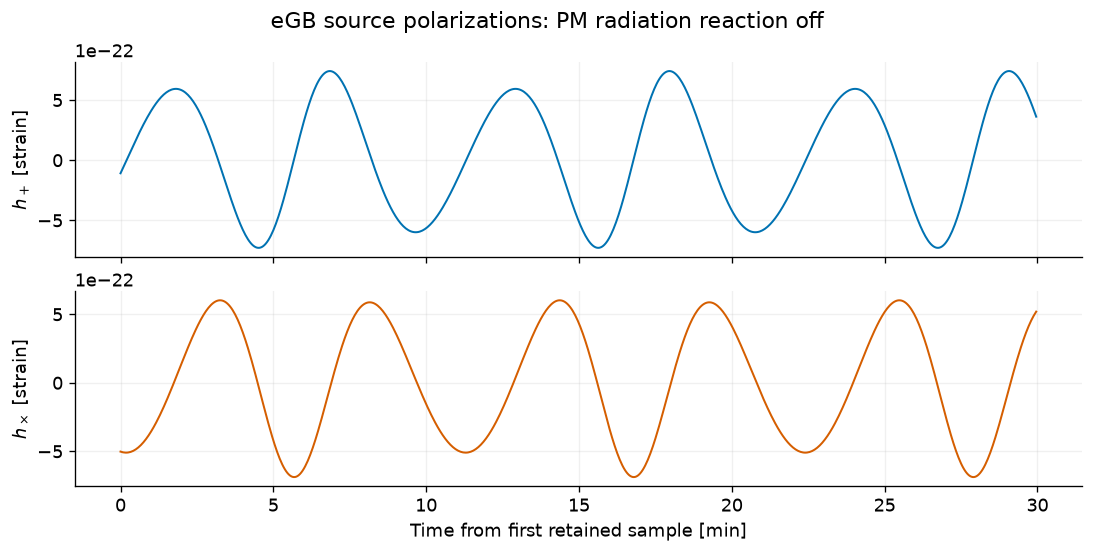

In [3]:
started = perf_counter()
sampled = sampled_polarizations(
    source, source_times, physics_mode="1pn", evolution_mode="fixed",
    source_backend="jax", device="cpu", order=39,
)
jax.block_until_ready(sampled.values)
source_first_s = perf_counter()-started
values = np.asarray(sampled.values)
assert values.shape == (2, source_times.size)
assert values.dtype == np.float64 and np.all(np.isfinite(values))
print(f"First source call, including compilation: {source_first_s:.3f} s")

fig, axes = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True, constrained_layout=True)
for ax, component, label, color in zip(
    axes, values[:, keep], (r"$h_+$", r"$h_\times$"), ("#0072B2", "#D55E00")
):
    ax.plot(time_minutes[view], component[view], color=color, linewidth=1.2)
    ax.set_ylabel(label + " [strain]")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.grid(alpha=.18)
axes[-1].set_xlabel("Time from first retained sample [min]")
fig.suptitle("eGB source polarizations: PM radiation reaction off")
plt.show()

## 3. Apply STRIDE with retarded-emitter geometry

The orbit adapter returns detector-only geometry: directed light times in
seconds, positions in light-seconds, and unit arm directions. The default
ESA-trailing orbit is transformed consistently into the source ecliptic
frame. The emitter is evaluated at its retarded time.

The stream owns a bounded detector cache. Each call evaluates the proposed
sky and polarization tensors. XYZ output is real, dimensionless fractional
frequency with shape `(3, N)`. Source interpolation order is 39 and TDI
measurement interpolation order is 25; second-generation TDI is used.

In [4]:
with warnings.catch_warnings(record=True) as orbit_warnings:
    warnings.simplefilter("always")
    orbit = default_lisaorbits("esa-trailing")
# Preserve upstream warning messages without embedding machine-specific paths.
for warning in orbit_warnings:
    print(f"{warning.category.__name__}: {warning.message}")
geometry_counter = {"calls": 0}

def retarded_geometry(query_times):
    geometry_counter["calls"] += 1
    return geometry_from_lisaorbits(orbit, query_times, frame="ecliptic")

stride = StreamedDetectorResponse(
    times, retarded_geometry, device="cpu", generation=2,
    measurement_order=25, padding_order=121,
    block_samples=32768, cache_bytes=256*1024**2,
    geometry_prescription="eGB retarded emitter; ESA trailing; ecliptic",
)

def evaluate_stride(detector, proposed_source, source_samples):
    return detector.sampled_response(
        source_samples, proposed_source.propagation_direction(),
        *proposed_source.polarization_basis(),
        order=39, polarization_angle=proposed_source.psi,
    )

started = perf_counter()
xyz_retarded = evaluate_stride(stride, source, sampled)
stride_first_s = perf_counter()-started
assert xyz_retarded.shape == (3, N) and np.all(np.isfinite(xyz_retarded))

started = perf_counter()
xyz_repeated = evaluate_stride(stride, source, sampled)
stride_repeated_s = perf_counter()-started
assert np.array_equal(xyz_repeated, xyz_retarded)

print(json.dumps({
    "first_STRIDE_response_s": stride_first_s,
    "repeated_response_s": stride_repeated_s,
    "detector_cache_MiB": stride.cached_bytes/1024**2,
    "geometry_provider_calls": geometry_counter["calls"],
}, indent=2))

You may also open an issue at https://gitlab.esa.int/lisa-sgs/commons/lisa-constants to warn that lisaconstants is not compatible with astropy v8.0.0


{
  "first_STRIDE_response_s": 0.9725513340090401,
  "repeated_response_s": 0.004216458008158952,
  "detector_cache_MiB": 5.294853210449219,
  "geometry_provider_calls": 1
}


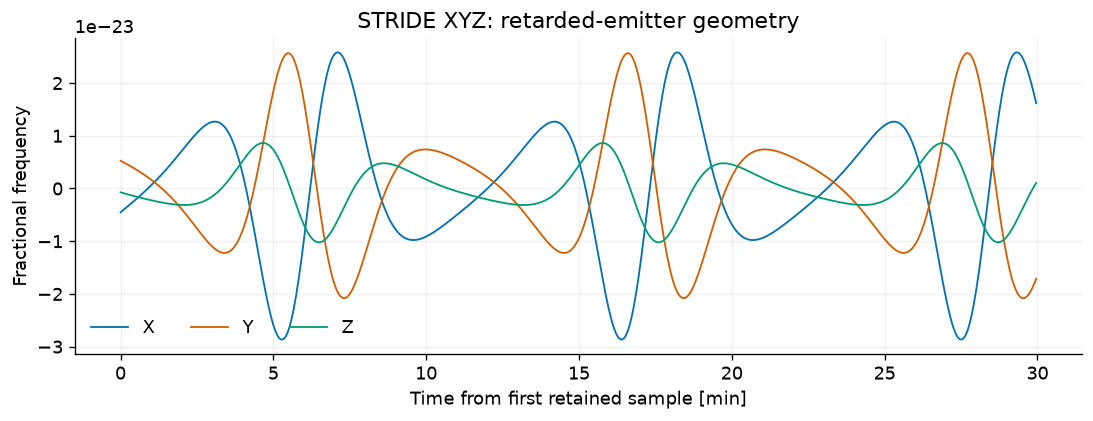

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.4), constrained_layout=True)
for channel, label, color in zip(xyz_retarded, "XYZ", ("#0072B2", "#D55E00", "#009E73")):
    ax.plot(time_minutes[view], channel[view], label=label, color=color, linewidth=1.1)
ax.set(xlabel="Time from first retained sample [min]", ylabel="Fractional frequency")
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.set_title("STRIDE XYZ: retarded-emitter geometry")
ax.legend(ncol=3, frameon=False)
ax.grid(alpha=.18)
plt.show()

### Change sky position while reusing the detector

This proposal changes only sky location and $\psi$, so the same intrinsic
plus/cross source table is valid. The response recomputes the projection and
wavefront times. The cached detector blocks are reused.

In [6]:
calls_before = geometry_counter["calls"]
proposal = replace(source, lambda_=2.1, beta=-.2, psi=.2)
xyz_proposal = evaluate_stride(stride, proposal, sampled)
assert geometry_counter["calls"] == calls_before
assert np.all(np.isfinite(xyz_proposal))
assert np.linalg.norm(xyz_proposal-xyz_retarded) > 0
print("Additional geometry queries for the changed sky:", geometry_counter["calls"]-calls_before)

Additional geometry queries for the changed sky: 0


## 4. Use native fastlisaresponse

Prepare the upstream response on its supplied equal-arm ephemeris. Only the
requested padded interval is configured at 37.5 s orbit-grid spacing. An
analysis can supply its own compatible numerical orbit file using the
`lisatools.detector.Orbits` interface.

The eGB-to-native tensor conversion includes the source polarization angle
and constructs the native input $h_+ + i h_\times$ in its own basis. eGB's
complex source uses $h_+ - i h_\times$ in the eGB basis. The native XYZ result
is mapped to the eGB/pyTDI global sign convention below. No amplitude, phase
or time is fitted.

This native projection uses instantaneous-emitter geometry. The following
comparison prepares STRIDE from the **same native orbit and emitter
prescription**, so it isolates the response implementations at the stated
interpolation settings. The retarded ESA-trailing example above has a
different detector prescription.

In [7]:
native_orbit = EqualArmlengthOrbits(force_backend="cpu")
ORBIT_DT_S = 37.5
orbit_grid = np.arange(int(np.ceil((source_times[-1]+300.)/ORBIT_DT_S))+1)*ORBIT_DT_S
assert orbit_grid[-1] <= native_orbit.t_base[-1]
native_orbit.configure(t_arr=orbit_grid)
native = pyResponseTDI(
    1./DT_S, source_times.size, order=25, tdi="2nd generation",
    orbits=native_orbit, tdi_chan="XYZ", force_backend="cpu",
)
assert native.num_pts == source_times.size
# Explicit receiver ordering for the checked native interface.
native.link_space_craft_0_in = native.response_orbits.link_space_craft_r

h_native = complex_polarizations(source, values)  # native h_plus + i*h_cross
assert h_native.dtype == np.complex128
started = perf_counter()
native.get_projections(h_native, source.lambda_, source.beta, t0=MARGIN_S)
xyz_native = -np.stack(native.get_tdi_delays())[:, keep]
native_first_s = perf_counter()-started
assert xyz_native.shape == (3, N) and np.all(np.isfinite(xyz_native))
print(f"Native projection + TDI first call: {native_first_s:.3f} s")

Native projection + TDI first call: 0.005 s


In [8]:
def native_instantaneous_geometry(query_times):
    positions = {
        spacecraft: native_orbit.get_pos(query_times, spacecraft)/C_M_PER_S
        for spacecraft in (1, 2, 3)
    }
    senders, receivers, directions, delays = [], [], [], []
    for link in LINK_LABELS:
        receiver, emitter = map(int, link)
        sender_position = positions[emitter]
        receiver_position = positions[receiver]
        separation = receiver_position-sender_position
        senders.append(sender_position)
        receivers.append(receiver_position)
        directions.append(separation/np.linalg.norm(separation, axis=-1)[:, None])
        delays.append(native_orbit.get_light_travel_times(query_times, int(link)))
    return dict(times=query_times, n=np.array(directions), length=np.array(delays),
                p_sender=np.array(senders), p_receiver=np.array(receivers))

matched_stride = StreamedDetectorResponse(
    times, native_instantaneous_geometry, device="cpu", generation=2,
    measurement_order=25, padding_order=121,
    block_samples=32768, cache_bytes=256*1024**2,
    geometry_prescription="matched native instantaneous emitter",
)
xyz_matched = evaluate_stride(matched_stride, source, sampled)
assert np.all(np.isfinite(xyz_matched))
reference_norm = np.linalg.norm(xyz_matched)
assert reference_norm > 0
relative_error = float(np.linalg.norm(xyz_native-xyz_matched)/reference_norm)
print(f"Same-input XYZ relative L2 difference: {relative_error:.6e}")

Same-input XYZ relative L2 difference: 7.937535e-06


## 5. Inspect the waveform and residual

The upper panel shows the matched-geometry X channel. The lower panel shows
the difference divided by the RMS of STRIDE's X channel over the complete
retained record; no division by individual zero-crossing samples is used.
The printed relative $L^2$ value includes **all XYZ channels and all retained
samples**. These are detector-response comparisons on the same polarizations;
source-model overlaps require a separate calculation.

The displayed times are single first/repeated calls with different setup
boundaries. They illustrate usage and compilation/cache effects. A controlled
speed comparison needs matched hardware, repeated synchronized measurements,
and independently qualified accuracy settings.

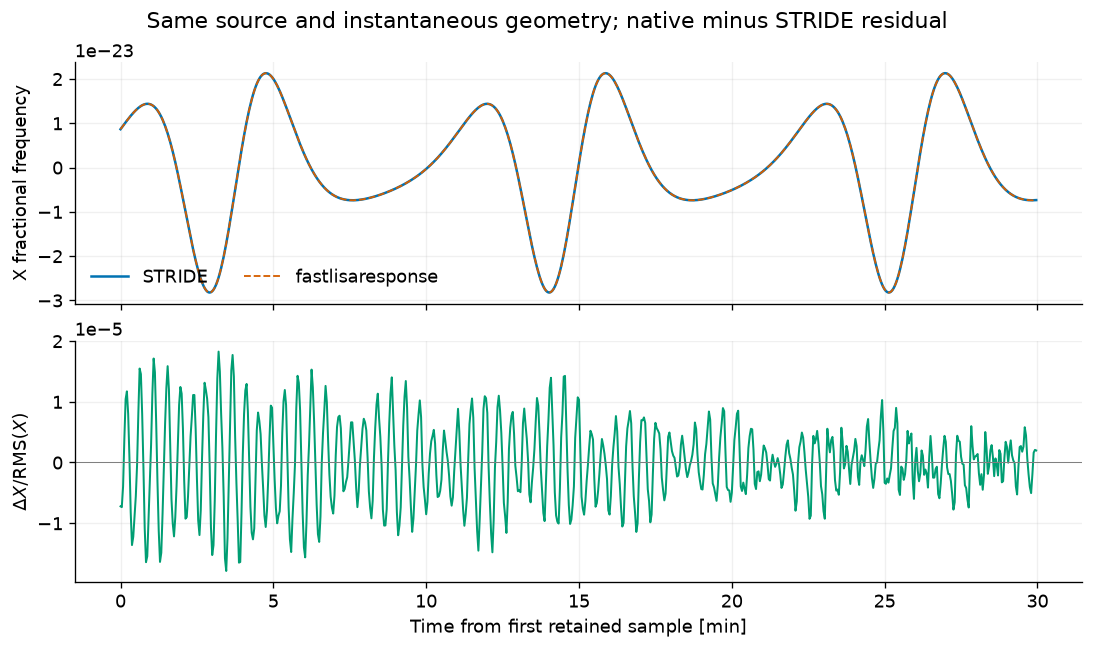

In [9]:
x_rms = np.sqrt(np.mean(xyz_matched[0]**2))
assert x_rms > 0
residual = (xyz_native[0]-xyz_matched[0])/x_rms
fig, axes = plt.subplots(2, 1, figsize=(9, 5.3), sharex=True, constrained_layout=True)
axes[0].plot(time_minutes[view], xyz_matched[0, view], color="#0072B2", label="STRIDE", linewidth=1.5)
axes[0].plot(time_minutes[view], xyz_native[0, view], color="#D55E00", label="fastlisaresponse", linestyle="--", linewidth=1.1)
axes[0].set_ylabel("X fractional frequency")
axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[0].legend(ncol=2, frameon=False)
axes[1].plot(time_minutes[view], residual[view], color="#009E73", linewidth=1.2)
axes[1].axhline(0., color=".5", linewidth=.6)
axes[1].set(ylabel=r"$\Delta X / \mathrm{RMS}(X)$", xlabel="Time from first retained sample [min]")
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
for ax in axes:
    ax.grid(alpha=.18)
fig.suptitle("Same source and instantaneous geometry; native minus STRIDE residual")
plt.show()

## Parameter changes, PM evolution and optional backends

| Change | Recompute |
| --- | --- |
| Masses, eccentricity, mean motion, inclination or source phase | Source polarizations and their response; keep compatible detector blocks |
| Sky position or polarization angle only | Projection and wavefront times; reuse the same source table and detector blocks |
| Orbit, detector grid, cadence or TDI interpolation settings | A new detector preparation; rebuild the source grid when coverage or cadence changes |
| Evolution prescription | Regenerate the source with the chosen physical model |

For PM evolution, regenerate the source using the existing NumPy/SciPy path:

```python
sampled_pm = sampled_polarizations(
    source, source_times, physics_mode="1pn", evolution_mode="peters_mathews",
    source_backend="numpy", device="cpu", order=39,
)
xyz_pm = evaluate_stride(stride, source, sampled_pm)
```

For the optional Numba CPU backend, install `.[cpu]`, prepare a new stream
with `backend="numba"`, and pass `sampled.to_host()`. The remaining source,
sky and geometry contracts are the same. See the
[executable eGB + STRIDE example](../egb_stride.py) for a complete command.

The executable examples also include CUDA usage. Install mutually compatible
JAX GPU, native fastlisaresponse CUDA and CuPy packages using their official
instructions, then run on an allocated NVIDIA GPU:

```sh
python examples/egb_stride.py --device gpu --source-backend jax
python examples/egb_fastlisaresponse.py --backend cuda12x --source-backend jax --compare-stride
```

Fixed-element eGB strain can remain on the GPU and be shared with CuPy using
DLPack; PM source evolution in this implementation uses the CPU and an
explicit transfer. Float64, source support and numerical accuracy must be
checked for the chosen hardware and settings. This notebook's executed
outputs are CPU examples; it launches no GPU or annual job.

For a longer observation, choose the retained sample count from
$N=T_\mathrm{obs}/\Delta t$, verify orbit/source support, and budget memory for
the source and returned arrays in addition to the bounded detector cache.
Streaming can retain bounded detector state while the full source table and
collected output remain additional allocations.

Please cite the eGB/STRIDE work as appropriate and
[Katz et al., arXiv:2204.06633](https://arxiv.org/abs/2204.06633) when using
fastlisaresponse. The native
[API documentation](https://mikekatz04.github.io/lisa-on-gpu/user/main.html)
defines its polarization, orbit and backend contracts.